In [19]:
# Importing libraries
import numpy as np
import pandas as pd
from time import time

# Visualization Libraries
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.legend_handler import HandlerLine2D
import seaborn as sns

# Modeling Libraries (Import)
from sklearn.preprocessing import LabelEncoder, MinMaxScaler, RobustScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, fbeta_score, roc_auc_score, roc_curve, auc, make_scorer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier, AdaBoostClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.feature_selection import SelectKBest, chi2

In [20]:
findex = pd.read_csv("GlobalFindexDatabase2025.csv")
plfs = pd.read_csv("mhhQPlfs.csv")
hces = pd.read_csv("Level1.csv")

print("Findex:", findex.shape)
print("PLFS:", plfs.shape)
print("HCES:", hces.shape)

/tmp/ipykernel_5405/3411533648.py:1: DtypeWarning: Columns (4,5) have mixed types. Specify dtype option on import or set low_memory=False.
  findex = pd.read_csv("GlobalFindexDatabase2025.csv")


Findex: (8577, 438)
PLFS: (401928, 39)
HCES: (152133, 3)


In [21]:
display(findex.head(3))
display(plfs.head(3))
display(hces.head(3))

,countrynewwb,codewb,year,pop_adult,regionwb24_hi,incomegroupwb24,group,group2,account_t_d,fiaccount_t_d,...,con12m_s,con26lm_s,con12w_s,con2f_s,con13_s,con26m_s,con28lm_s,con5a_s,con17c_s,con32h_s
0,Afghanistan,AFG,2011,14575546.0,South Asia (excluding high income),Low income,all,all,0.090050,0.090050,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Albania,ALB,2011,2281010.0,Europe & Central Asia (excluding high income),Upper middle income,all,all,0.282681,0.282681,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Algeria,DZA,2011,26251587.0,Middle East & North Africa (excluding high inc...,Lower middle income,all,all,0.332861,0.332861,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,file_id,sch,qtr,month,visit,sec,st,dc,nss_reg,bstrm,...,inf_srl,sur_date,sur_time,nsc,mult,totalsd,zst,caph,smallh,panel
0,QH1,104,Q2,4,V4,1,28,1,281,D001,...,2,16042025,25,6,817538,1,1161,169,4,5
1,QH1,104,Q2,4,V4,1,28,1,281,D001,...,2,17042025,25,6,193500,1,1161,60,6,5
2,QH1,104,Q2,4,V4,1,28,1,281,D001,...,2,17042025,22,6,1025550,1,1161,106,2,5


Unnamed: 0  \
HCES 2024 42499 1 24 243 2 13 1 10 2 2421 5 NaN 3 17 H 1           1   
          42494 1 24 243 2 21 1 1  1 2421 1 NaN 2 1  H 1           1   
                                                3 1  H 1           1   

                                                          Unnamed: 1  38404  
HCES 2024 42499 1 24 243 2 13 1 10 2 2421 5 NaN 3 17 H 1         NaN  38404  
          42494 1 24 243 2 21 1 1  1 2421 1 NaN 2 1  H 1         NaN  15375  
                                                3 1  H 1         NaN  18812

In [22]:
# Find potentially useful behavioral variables

keywords = [
    "give", "giving", "donat", "charit", "help",
    "save", "saving", "borrow", "money",
    "pay", "payment", "remit", "volunt",
    "trust", "income", "financial", "employ"
]

matching_columns = []

for col in findex.columns:
    if any(word in col.lower() for word in keywords):
        matching_columns.append(col)

print("Potentially relevant variables:")
for col in matching_columns:
    print(col)

print("\nTotal:", len(matching_columns))

Potentially relevant variables:
incomegroupwb24
borrow_any_t_d
merchant_pay
save_any_t_d

Total: 4


In [23]:
# Show ALL Findex columns in an easy-to-read numbered list

for i, col in enumerate(findex.columns):
    print(i, col)

0 countrynewwb
1 codewb
2 year
3 pop_adult
4 regionwb24_hi
5 incomegroupwb24
6 group
7 group2
8 account_t_d
9 fiaccount_t_d
10 mobileaccount_t_d
11 borrow_any_t_d
12 fin4_d
13 dig_acc
14 fin11_2a
15 fin11a
16 fin11b
17 fin11c
18 fin11f
19 fin11d
20 fin11e
21 fin14a
22 fin14b
23 fin14c
24 fin14d
25 fin13_1a
26 fin13_1b
27 fin26a
28 fin26b
29 fin27a
30 fin27b
31 fin17f
32 fin17a_17a1_d
33 fin17a
34 fin17b
35 fin17c
36 fin22d
37 fin22e
38 fin22a_22a1_22g_d
39 fin22a
40 fin22a_22g
41 fin22a_1
42 fin22b
43 fin22c
44 fin24sav
45 fin24fam
46 fin24work
47 fin24bor
48 fin24sell
49 fin24other
50 fin24aVD
51 fin24aSD
52 fin24aND
53 fin24aSD_ND
54 fin24aP
55 fin24aN
56 fin24sav_SD_ND
57 fin24fam_SD_ND
58 fin24work_SD_ND
59 fin24bor_SD_ND
60 fin24sell_SD_ND
61 fin24other_SD_ND
62 fin24sav_VD
63 fin24fam_VD
64 fin24work_VD
65 fin24bor_VD
66 fin24sell_VD
67 fin24other_VD
68 fh1
69 fin28
70 fh2
71 fin29
72 fin31a_31b
73 fin30
74 fin31a
75 fin31b
76 fin31d
77 fin32_33_34a
78 fin32_33_34b
79 fin32_33_34

In [24]:
# Show the first row's values for the variables we found

display(
    findex[
        ["incomegroupwb24",
         "borrow_any_t_d",
         "merchant_pay",
         "save_any_t_d"]
    ].head(20)
)

,incomegroupwb24,borrow_any_t_d,merchant_pay,save_any_t_d
0,Low income,NaN,NaN,NaN
1,Upper middle income,NaN,NaN,NaN
2,Lower middle income,NaN,NaN,NaN
3,Lower middle income,NaN,NaN,NaN
4,Upper middle income,NaN,NaN,NaN
5,Upper middle income,NaN,NaN,NaN
6,High income,NaN,NaN,NaN
7,High income,NaN,NaN,NaN
8,Upper middle income,NaN,NaN,NaN
9,High income,NaN,NaN,NaN


In [25]:
  hig = pd.read_excel("Final1.xlsx")
print("Shape:", hig.shape)
print("\nColumns:")
print(hig.columns.tolist())

display(hig.head())

Shape: (7225, 61)

Columns:
['ID', 'State', 'VS_NAME', 'VS_NO', 'cash_family_friends', 'cash_beggars', 'cash_religious_orgs', 'cash_non-religious_orgs', 'overall_cash_giving', 'cash_none', 'cash_refused', 'payment_method', 'in-kind_family_friends', 'in-kind_beggars', 'in-kind_religious_orgs', 'in-kind_non-religious_orgs', 'overall_in-kind_giving', 'in-kind_none', 'in-kind_refused', 'volunteer_religious', 'volunteer_non-religious', 'overall_volunteer', 'volunteer_none', 'volunteer_refused', 'donation_amount', 'primary_recipient', 'time_spent_for_causes', 'learning_channel', 'learning_channel_combinedSM', 'television', 'electric_fan', 'air_conditioner', 'bicycle', 'two_wheeler', 'washing_machine', 'computer', 'car_or_heavy_vehicle', 'HH_position', 'gender', 'age', 'state', 'residence_type', 'district', 'religion', 'social_category', 'highest_education', 'cash_in-kind_giving', 'combined_ages', 'region', 'assetclass', 'overall_giving', 'Range_donations', 'Recipient_religious', 'Recipient_n

,ID,State,VS_NAME,VS_NO,cash_family_friends,cash_beggars,cash_religious_orgs,cash_non-religious_orgs,overall_cash_giving,cash_none,...,Range_donations,Recipient_religious,Recipient_non.religious,Recipient_beggars,Recipient_family_friends,cons,consumption category,Edu category,Archetype,avg_HH_Size_FDQ_lvl3
0,10001,7,Valsad,179,0,0,1,0,1,0,...,Above 10000,1,0,1,0,9711.80325,High,High,Well-off Givers,4.416200
1,10002,7,SIDDHPUR,19,0,0,0,0,0,1,...,NaN,0,0,0,0,5652.24134,Low,Low,Grassroots Givers,4.612161
2,10003,7,Palanpur,12,0,0,0,0,0,1,...,NaN,1,0,1,0,4872.64932,Low,Low,Grassroots Givers,4.122367
3,10004,7,Dharampur,178,0,1,0,0,1,0,...,NaN,0,0,1,0,5716.69395,Low,High,Aspirational Givers,4.122367
4,10005,7,Choryasi,168,0,1,1,0,1,0,...,NaN,1,0,1,0,6910.74349,Low,High,Aspirational Givers,4.524150


In [26]:
findex = pd.read_csv("GlobalFindexDatabase2025.csv")

print("Shape:", findex.shape)
print("\nColumns:")
print(findex.columns.tolist())

display(findex.head())

Shape: (8577, 438)

Columns:
['countrynewwb', 'codewb', 'year', 'pop_adult', 'regionwb24_hi', 'incomegroupwb24', 'group', 'group2', 'account_t_d', 'fiaccount_t_d', 'mobileaccount_t_d', 'borrow_any_t_d', 'fin4_d', 'dig_acc', 'fin11_2a', 'fin11a', 'fin11b', 'fin11c', 'fin11f', 'fin11d', 'fin11e', 'fin14a', 'fin14b', 'fin14c', 'fin14d', 'fin13_1a', 'fin13_1b', 'fin26a', 'fin26b', 'fin27a', 'fin27b', 'fin17f', 'fin17a_17a1_d', 'fin17a', 'fin17b', 'fin17c', 'fin22d', 'fin22e', 'fin22a_22a1_22g_d', 'fin22a', 'fin22a_22g', 'fin22a_1', 'fin22b', 'fin22c', 'fin24sav', 'fin24fam', 'fin24work', 'fin24bor', 'fin24sell', 'fin24other', 'fin24aVD', 'fin24aSD', 'fin24aND', 'fin24aSD_ND', 'fin24aP', 'fin24aN', 'fin24sav_SD_ND', 'fin24fam_SD_ND', 'fin24work_SD_ND', 'fin24bor_SD_ND', 'fin24sell_SD_ND', 'fin24other_SD_ND', 'fin24sav_VD', 'fin24fam_VD', 'fin24work_VD', 'fin24bor_VD', 'fin24sell_VD', 'fin24other_VD', 'fh1', 'fin28', 'fh2', 'fin29', 'fin31a_31b', 'fin30', 'fin31a', 'fin31b', 'fin31d', 'fin32

/tmp/ipykernel_5405/91388598.py:1: DtypeWarning: Columns (4,5) have mixed types. Specify dtype option on import or set low_memory=False.
  findex = pd.read_csv("GlobalFindexDatabase2025.csv")


,countrynewwb,codewb,year,pop_adult,regionwb24_hi,incomegroupwb24,group,group2,account_t_d,fiaccount_t_d,...,con12m_s,con26lm_s,con12w_s,con2f_s,con13_s,con26m_s,con28lm_s,con5a_s,con17c_s,con32h_s
0,Afghanistan,AFG,2011,14575546.0,South Asia (excluding high income),Low income,all,all,0.090050,0.090050,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Albania,ALB,2011,2281010.0,Europe & Central Asia (excluding high income),Upper middle income,all,all,0.282681,0.282681,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Algeria,DZA,2011,26251587.0,Middle East & North Africa (excluding high inc...,Lower middle income,all,all,0.332861,0.332861,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Angola,AGO,2011,12779501.0,Sub-Saharan Africa (excluding high income),Lower middle income,all,all,0.392035,0.392035,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Argentina,ARG,2011,30685516.0,Latin America & Caribbean (excluding high income),Upper middle income,all,all,0.331302,0.331302,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [27]:
# Check our target variable
print("TARGET: overall_cash_giving")
print("\nValue counts:")
print(hig["overall_cash_giving"].value_counts(dropna=False))

print("\nPercentages:")
print(
    hig["overall_cash_giving"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
)

print("\nMissing values:")
print(hig["overall_cash_giving"].isna().sum())

TARGET: overall_cash_giving

Value counts:
overall_cash_giving
0    3979
1    3246
Name: count, dtype: int64

Percentages:
overall_cash_giving
0    55.07
1    44.93
Name: proportion, dtype: float64

Missing values:
0


In [28]:
# Inspect all columns and their data types
pd.set_option("display.max_rows", 100)

info = pd.DataFrame({
    "Column": hig.columns,
    "Type": hig.dtypes.astype(str),
    "Missing": hig.isna().sum(),
    "Missing_%": (hig.isna().mean() * 100).round(2),
    "Unique": hig.nunique(dropna=True)
})

display(info)

,Column,Type,Missing,Missing_%,Unique
ID,ID,int64,0,0.00,7225
State,State,int64,0,0.00,20
VS_NAME,VS_NAME,object,0,0.00,2727
VS_NO,VS_NO,int64,0,0.00,388
cash_family_friends,cash_family_friends,int64,0,0.00,2
cash_beggars,cash_beggars,int64,0,0.00,2
cash_religious_orgs,cash_religious_orgs,int64,0,0.00,2
cash_non-religious_orgs,cash_non-religious_orgs,int64,0,0.00,2
overall_cash_giving,overall_cash_giving,int64,0,0.00,2
cash_none,cash_none,int64,0,0.00,2


In [29]:
# Show the columns of our main dataset in a clean numbered list

for i, col in enumerate(hig.columns):
    print(f"{i:2}: {col}")

 0: ID
 1: State
 2: VS_NAME
 3: VS_NO
 4: cash_family_friends
 5: cash_beggars
 6: cash_religious_orgs
 7: cash_non-religious_orgs
 8: overall_cash_giving
 9: cash_none
10: cash_refused
11: payment_method
12: in-kind_family_friends
13: in-kind_beggars
14: in-kind_religious_orgs
15: in-kind_non-religious_orgs
16: overall_in-kind_giving
17: in-kind_none
18: in-kind_refused
19: volunteer_religious
20: volunteer_non-religious
21: overall_volunteer
22: volunteer_none
23: volunteer_refused
24: donation_amount
25: primary_recipient
26: time_spent_for_causes
27: learning_channel
28: learning_channel_combinedSM
29: television
30: electric_fan
31: air_conditioner
32: bicycle
33: two_wheeler
34: washing_machine
35: computer
36: car_or_heavy_vehicle
37: HH_position
38: gender
39: age
40: state
41: residence_type
42: district
43: religion
44: social_category
45: highest_education
46: cash_in-kind_giving
47: combined_ages
48: region
49: assetclass
50: overall_giving
51: Range_donations
52: Recipien

In [30]:
# ============================================
# STEP 1: Prepare HIG baseline dataset
# ============================================

# Make a copy so we don't accidentally modify the original
df = hig.copy()

# Target variable
target = "overall_cash_giving"

# Columns that directly describe the giving behavior
# We should NOT use these as predictors because they can cause data leakage.
giving_columns = [
    "cash_family_friends",
    "cash_beggars",
    "cash_religious_orgs",
    "cash_non-religious_orgs",
    "cash_none",
    "cash_refused",
    "overall_cash_giving",
    "in-kind_family_friends",
    "in-kind_beggars",
    "in-kind_religious_orgs",
    "in-kind_non-religious_orgs",
    "overall_in-kind_giving",
    "in-kind_none",
    "in-kind_refused",
    "volunteer_religious",
    "volunteer_non-religious",
    "overall_volunteer",
    "volunteer_none",
    "volunteer_refused",
    "donation_amount",
    "primary_recipient",
    "time_spent_for_causes"
]

# Keep only columns that actually exist
giving_columns = [c for c in giving_columns if c in df.columns]

# Candidate predictor columns
predictor_columns = [
    c for c in df.columns
    if c not in giving_columns
]

print("Target:", target)
print("\nNumber of candidate predictors:", len(predictor_columns))

print("\nCandidate predictors:")
for i, col in enumerate(predictor_columns):
    print(f"{i}: {col}")

Target: overall_cash_giving

Number of candidate predictors: 39

Candidate predictors:
0: ID
1: State
2: VS_NAME
3: VS_NO
4: payment_method
5: learning_channel
6: learning_channel_combinedSM
7: television
8: electric_fan
9: air_conditioner
10: bicycle
11: two_wheeler
12: washing_machine
13: computer
14: car_or_heavy_vehicle
15: HH_position
16: gender
17: age
18: state
19: residence_type
20: district
21: religion
22: social_category
23: highest_education
24: cash_in-kind_giving
25: combined_ages
26: region
27: assetclass
28: overall_giving
29: Range_donations
30: Recipient_religious
31: Recipient_non.religious
32: Recipient_beggars
33: Recipient_family_friends
34: cons
35: consumption category
36: Edu category
37: Archetype
38: avg_HH_Size_FDQ_lvl3


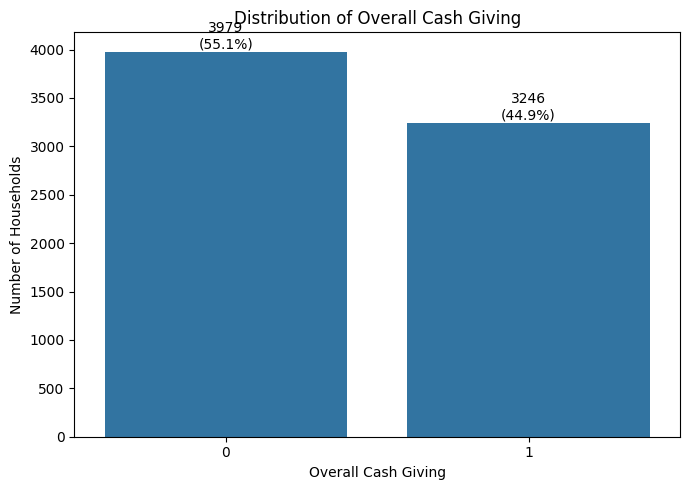

In [31]:
plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x="overall_cash_giving"
)

plt.title("Distribution of Overall Cash Giving")
plt.xlabel("Overall Cash Giving")
plt.ylabel("Number of Households")

# Add percentages above bars
total = len(df)

for p in ax.patches:
    count = int(p.get_height())
    percentage = count / total * 100
    ax.annotate(
        f"{count}\n({percentage:.1f}%)",
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

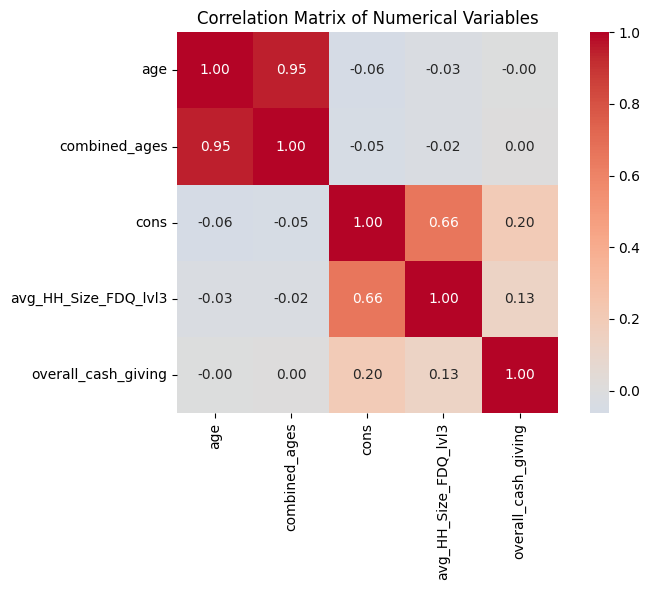

In [32]:
# EDA 2: Correlation among numerical variables

numeric_cols = [
    "age",
    "combined_ages",
    "cons",
    "avg_HH_Size_FDQ_lvl3",
    "overall_cash_giving"
]

corr = df[numeric_cols].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title("Correlation Matrix of Numerical Variables")
plt.tight_layout()
plt.show()

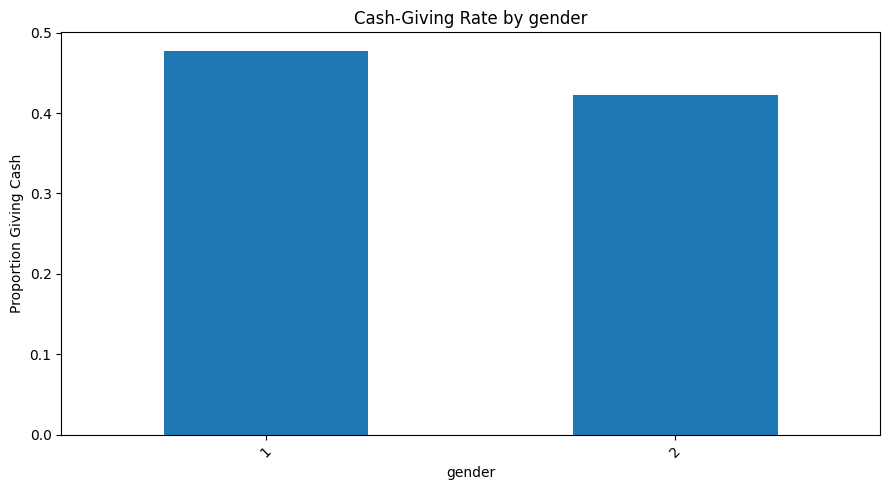

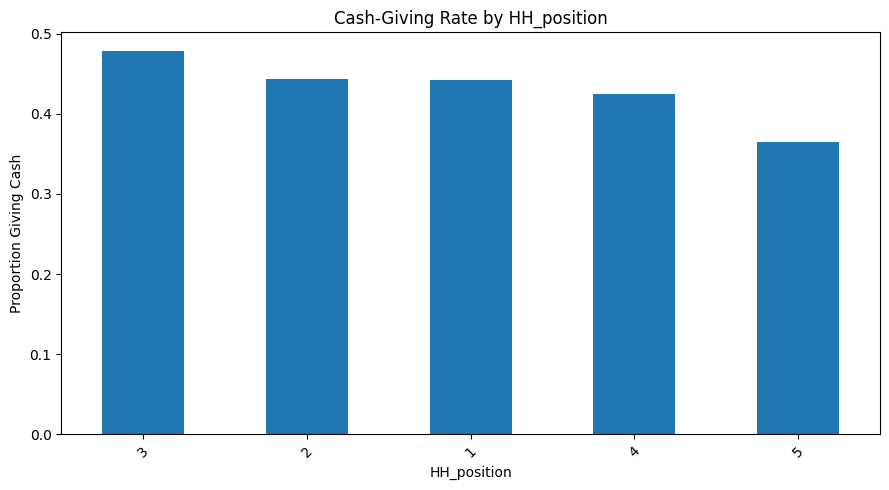

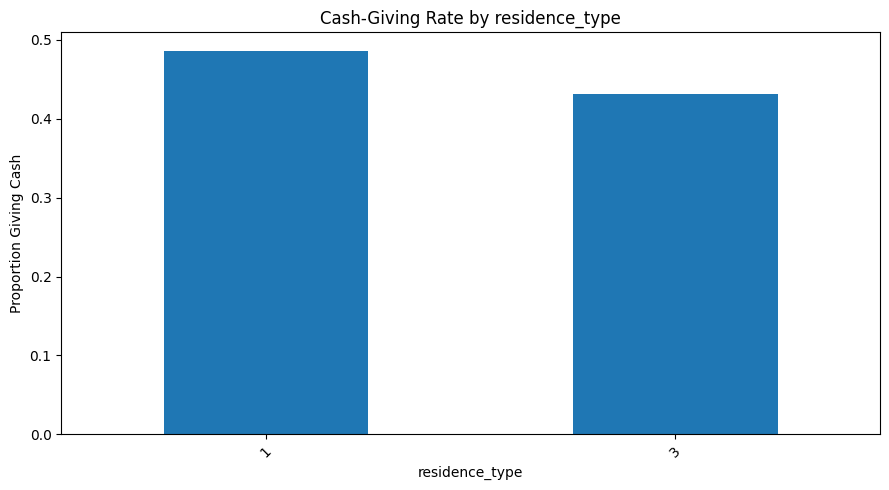

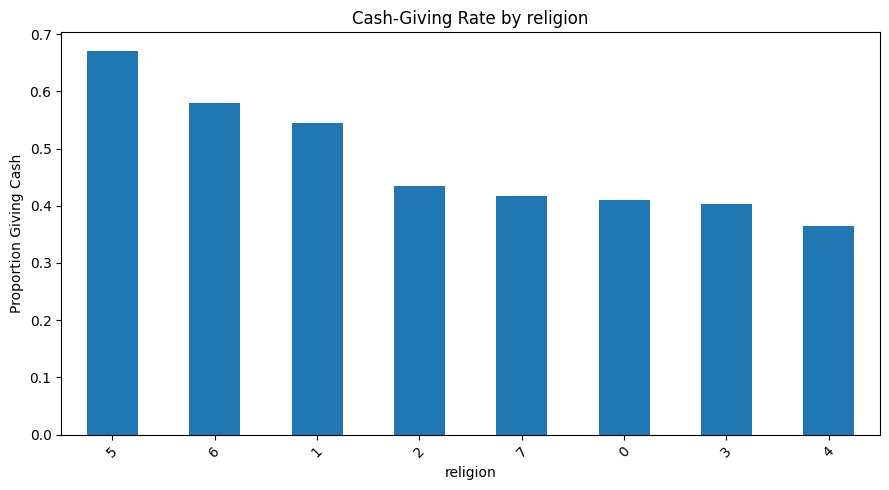

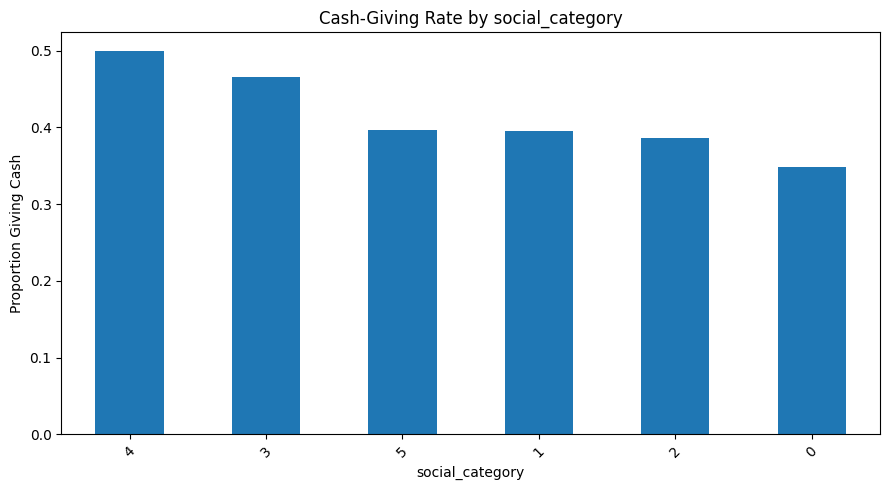

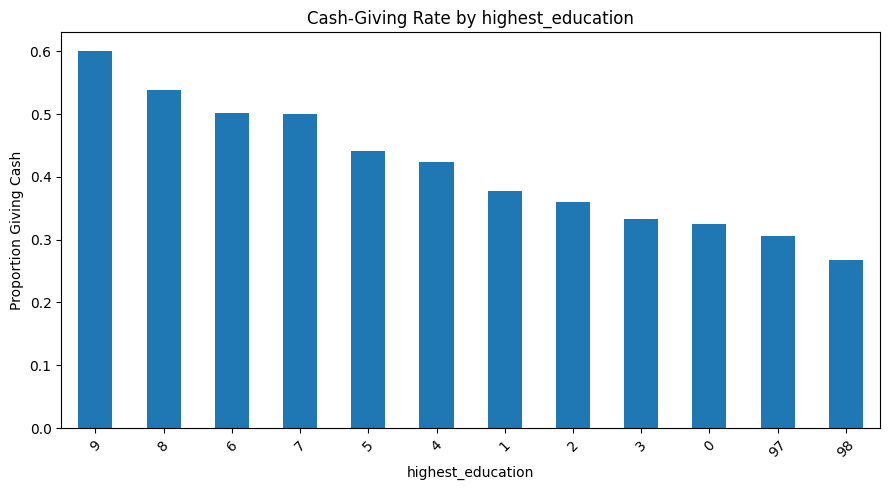

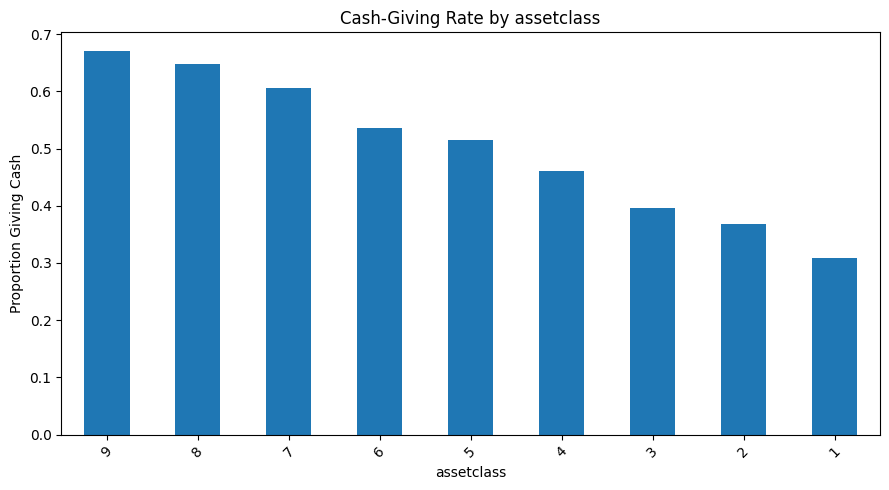

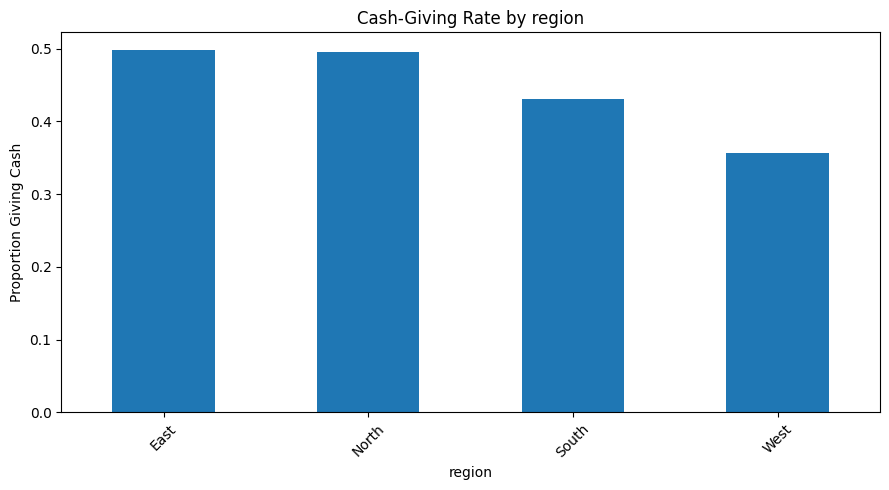

In [33]:
# EDA 4: Cash-giving rate by selected categorical variables

categorical_features = [
    "gender",
    "HH_position",
    "residence_type",
    "religion",
    "social_category",
    "highest_education",
    "assetclass",
    "region"
]

for col in categorical_features:

    rates = (
        df.groupby(col)["overall_cash_giving"]
        .mean()
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(9, 5))

    rates.plot(kind="bar")

    plt.title(f"Cash-Giving Rate by {col}")
    plt.xlabel(col)
    plt.ylabel("Proportion Giving Cash")
    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

In [34]:
# Check whether overall_cash_giving is directly derived from the cash-giving variables

cash_cols = [
    "cash_family_friends",
    "cash_beggars",
    "cash_religious_orgs",
    "cash_non-religious_orgs"
]

# Count how many cash-giving sources each household used
cash_source_count = df[cash_cols].sum(axis=1)

# Compare with the target
comparison = pd.DataFrame({
    "cash_source_count": cash_source_count,
    "overall_cash_giving": df["overall_cash_giving"]
})

print(comparison.groupby("overall_cash_giving")["cash_source_count"].describe())

print("\nCross-tabulation:")
print(pd.crosstab(
    comparison["cash_source_count"],
    comparison["overall_cash_giving"],
    normalize="index"
))

                      count      mean       std  min  25%  50%  75%  max
overall_cash_giving                                                     
0                    3979.0  0.000000  0.000000  0.0  0.0  0.0  0.0  0.0
1                    3246.0  1.354282  0.599583  1.0  1.0  1.0  2.0  4.0

Cross-tabulation:
overall_cash_giving    0    1
cash_source_count            
0                    1.0  0.0
1                    0.0  1.0
2                    0.0  1.0
3                    0.0  1.0
4                    0.0  1.0


In [35]:
# Create a clean modeling dataset

target = "overall_cash_giving"

# Variables that directly determine the target — remove to avoid leakage
leakage_cols = [
    "cash_family_friends",
    "cash_beggars",
    "cash_religious_orgs",
    "cash_non-religious_orgs"
]

# Also remove identifiers / variables that shouldn't be predictive features
drop_cols = [
    "ID",
    target
] + leakage_cols

model_df = df.drop(columns=drop_cols, errors="ignore").copy()

print("Original shape:", df.shape)
print("Modeling shape:", model_df.shape)

print("\nRemaining columns:")
for i, col in enumerate(model_df.columns):
    print(f"{i}: {col}")

Original shape: (7225, 61)
Modeling shape: (7225, 55)

Remaining columns:
0: State
1: VS_NAME
2: VS_NO
3: cash_none
4: cash_refused
5: payment_method
6: in-kind_family_friends
7: in-kind_beggars
8: in-kind_religious_orgs
9: in-kind_non-religious_orgs
10: overall_in-kind_giving
11: in-kind_none
12: in-kind_refused
13: volunteer_religious
14: volunteer_non-religious
15: overall_volunteer
16: volunteer_none
17: volunteer_refused
18: donation_amount
19: primary_recipient
20: time_spent_for_causes
21: learning_channel
22: learning_channel_combinedSM
23: television
24: electric_fan
25: air_conditioner
26: bicycle
27: two_wheeler
28: washing_machine
29: computer
30: car_or_heavy_vehicle
31: HH_position
32: gender
33: age
34: state
35: residence_type
36: district
37: religion
38: social_category
39: highest_education
40: cash_in-kind_giving
41: combined_ages
42: region
43: assetclass
44: overall_giving
45: Range_donations
46: Recipient_religious
47: Recipient_non.religious
48: Recipient_beggar

In [36]:
# Create a clean modeling dataset

target = "overall_cash_giving"

# Variables that directly determine the target — remove to avoid leakage
leakage_cols = [
    "cash_family_friends",
    "cash_beggars",
    "cash_religious_orgs",
    "cash_non-religious_orgs"
]

# Also remove identifiers / variables that shouldn't be predictive features
drop_cols = [
    "ID",
    target
] + leakage_cols

model_df = df.drop(columns=drop_cols, errors="ignore").copy()

print("Original shape:", df.shape)
print("Modeling shape:", model_df.shape)

print("\nRemaining columns:")
for i, col in enumerate(model_df.columns):
    print(f"{i}: {col}")

Original shape: (7225, 61)
Modeling shape: (7225, 55)

Remaining columns:
0: State
1: VS_NAME
2: VS_NO
3: cash_none
4: cash_refused
5: payment_method
6: in-kind_family_friends
7: in-kind_beggars
8: in-kind_religious_orgs
9: in-kind_non-religious_orgs
10: overall_in-kind_giving
11: in-kind_none
12: in-kind_refused
13: volunteer_religious
14: volunteer_non-religious
15: overall_volunteer
16: volunteer_none
17: volunteer_refused
18: donation_amount
19: primary_recipient
20: time_spent_for_causes
21: learning_channel
22: learning_channel_combinedSM
23: television
24: electric_fan
25: air_conditioner
26: bicycle
27: two_wheeler
28: washing_machine
29: computer
30: car_or_heavy_vehicle
31: HH_position
32: gender
33: age
34: state
35: residence_type
36: district
37: religion
38: social_category
39: highest_education
40: cash_in-kind_giving
41: combined_ages
42: region
43: assetclass
44: overall_giving
45: Range_donations
46: Recipient_religious
47: Recipient_non.religious
48: Recipient_beggar

In [37]:
#Feature engineering

In [38]:
# Check data types and NAN

print("Data types:")
print(model_df.dtypes)

print("\nMissing values:")
missing = model_df.isnull().sum()
print(missing[missing > 0].sort_values(ascending=False))

Data types:
State                            int64
VS_NAME                         object
VS_NO                            int64
cash_none                        int64
cash_refused                     int64
payment_method                 float64
in-kind_family_friends           int64
in-kind_beggars                  int64
in-kind_religious_orgs           int64
in-kind_non-religious_orgs       int64
overall_in-kind_giving           int64
in-kind_none                     int64
in-kind_refused                  int64
volunteer_religious              int64
volunteer_non-religious          int64
overall_volunteer                int64
volunteer_none                   int64
volunteer_refused                int64
donation_amount                float64
primary_recipient              float64
time_spent_for_causes          float64
learning_channel                 int64
learning_channel_combinedSM      int64
television                       int64
electric_fan                     int64
air_condition

In [39]:
# Finding NAN

missing_summary = pd.DataFrame({
    "missing_count": model_df.isnull().sum(),
    "missing_percent": model_df.isnull().mean() * 100
})

missing_summary = missing_summary[
    missing_summary["missing_count"] > 0
].sort_values("missing_count", ascending=False)

print(missing_summary)

                       missing_count  missing_percent
Range_donations                 4393        60.802768
payment_method                  3978        55.058824
donation_amount                 2329        32.235294
primary_recipient               2329        32.235294
time_spent_for_causes           2329        32.235294
Archetype                        302         4.179931
cons                             198         2.740484
consumption category             198         2.740484
Edu category                     120         1.660900


In [40]:
# Compare cash-giving rates for households WITH and WITHOUT each missing value

missing_cols = [
    "Range_donations",
    "payment_method",
    "donation_amount",
    "primary_recipient",
    "time_spent_for_causes",
    "Archetype",
    "cons",
    "consumption category",
    "Edu category"
]

for col in missing_cols:
    print(f"\n{'='*60}")
    print(f"{col}")
    print(f"{'='*60}")

    temp = pd.DataFrame({
        "is_missing": model_df[col].isna(),
        "overall_cash_giving": df["overall_cash_giving"]
    })

    print(
        temp.groupby("is_missing")["overall_cash_giving"]
        .agg(["count", "mean"])
    )


Range_donations
            count      mean
is_missing                 
False        2832  0.771540
True         4393  0.241521

payment_method
            count      mean
is_missing                 
False        3247  0.999692
True         3978  0.000000

donation_amount
            count     mean
is_missing                
False        4896  0.66299
True         2329  0.00000

primary_recipient
            count     mean
is_missing                
False        4896  0.66299
True         2329  0.00000

time_spent_for_causes
            count     mean
is_missing                
False        4896  0.66299
True         2329  0.00000

Archetype
            count      mean
is_missing                 
False        6923  0.456738
True          302  0.278146

cons
            count      mean
is_missing                 
False        7027  0.455102
True          198  0.242424

consumption category
            count      mean
is_missing                 
False        7027  0.455102
True         

In [41]:
# Examine the values and relationships of the key donation-related variables

key_cols = [
    "Range_donations",
    "payment_method",
    "donation_amount",
    "primary_recipient",
    "time_spent_for_causes"
]

for col in key_cols:
    print(f"\n{'='*70}")
    print(f"{col}")
    print(f"{'='*70}")
    print("Unique values:")
    print(model_df[col].dropna().unique()[:20])
    print("\nValue counts:")
    print(model_df[col].value_counts(dropna=False).head(15))


Range_donations
Unique values:
['Above 10000' '1001–5000' 'Under 1000' '5001–10000']

Value counts:
Range_donations
NaN            4393
1001–5000      1225
Under 1000      881
Above 10000     436
5001–10000      290
Name: count, dtype: int64

payment_method
Unique values:
[1. 0. 2. 4. 3.]

Value counts:
payment_method
NaN    3978
1.0    2984
2.0     133
0.0      63
3.0      35
4.0      32
Name: count, dtype: int64

donation_amount
Unique values:
[15000.     0.  5000.  1500.   450.   200.  1100.  2500.  3500.  3000.
 12000.   400.   500.  2750. 12500.  6000.  1000. 10000. 25000.  4000.]

Value counts:
donation_amount
NaN        2329
0.0        2064
1000.0      258
500.0       238
5000.0      197
2000.0      194
10000.0     150
3000.0      142
100.0       119
1500.0      102
300.0        84
200.0        84
20000.0      75
4000.0       63
2500.0       61
Name: count, dtype: int64

primary_recipient
Unique values:
[3. 2. 1. 0. 4.]

Value counts:
primary_recipient
NaN    2329
3.0    1874
2

In [42]:
# ============================================
# BASELINE MODEL DATASET
# ============================================

target = "overall_cash_giving"

# Directly related to the outcome / post-outcome information
leakage_cols = [
    "cash_family_friends",
    "cash_beggars",
    "cash_religious_orgs",
    "cash_non-religious_orgs",
    "Range_donations",
    "payment_method",
    "donation_amount",
    "primary_recipient",
    "time_spent_for_causes"
]

# IDs / administrative columns
id_cols = [
    "ID",
    "VS_NAME",
    "VS_NO"
]

# Combine and remove only columns that exist
remove_cols = [
    col for col in leakage_cols + id_cols
    if col in hig.columns
]

# X = predictors
X = hig.drop(columns=remove_cols + [target], errors="ignore").copy()

# y = target
y = hig[target].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nRemaining features:")
print(X.columns.tolist())

X shape: (7225, 48)
y shape: (7225,)

Target distribution:
overall_cash_giving
0    3979
1    3246
Name: count, dtype: int64

Remaining features:
['State', 'cash_none', 'cash_refused', 'in-kind_family_friends', 'in-kind_beggars', 'in-kind_religious_orgs', 'in-kind_non-religious_orgs', 'overall_in-kind_giving', 'in-kind_none', 'in-kind_refused', 'volunteer_religious', 'volunteer_non-religious', 'overall_volunteer', 'volunteer_none', 'volunteer_refused', 'learning_channel', 'learning_channel_combinedSM', 'television', 'electric_fan', 'air_conditioner', 'bicycle', 'two_wheeler', 'washing_machine', 'computer', 'car_or_heavy_vehicle', 'HH_position', 'gender', 'age', 'state', 'residence_type', 'district', 'religion', 'social_category', 'highest_education', 'cash_in-kind_giving', 'combined_ages', 'region', 'assetclass', 'overall_giving', 'Recipient_religious', 'Recipient_non.religious', 'Recipient_beggars', 'Recipient_family_friends', 'cons', 'consumption category', 'Edu category', 'Archetype

In [43]:
# ============================================
# TRAIN / TEST SPLIT + PREPROCESSING
# ============================================

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Identify numerical and categorical columns
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("\nTraining rows:", len(X_train))
print("Testing rows:", len(X_test))


Numerical features: 42
Categorical features: 6

Training rows: 5780
Testing rows: 1445


In [44]:
# ============================================
# BASELINE MODEL: LOGISTIC REGRESSION
# ============================================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Create the model
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train
logistic_model.fit(X_train, y_train)

# Predict on unseen test data
y_pred = logistic_model.predict(X_test)
y_prob = logistic_model.predict_proba(X_test)[:, 1]

# Evaluate
print("=== LOGISTIC REGRESSION RESULTS ===")

print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall   :", round(recall_score(y_test, y_pred), 4))
print("F1 Score :", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

=== LOGISTIC REGRESSION RESULTS ===
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 Score : 1.0
ROC-AUC  : 1.0

Confusion Matrix:
[[796   0]
 [  0 649]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       796
           1       1.00      1.00      1.00       649

    accuracy                           1.00      1445
   macro avg       1.00      1.00      1.00      1445
weighted avg       1.00      1.00      1.00      1445



In [45]:
# ============================================
# CHECK WHICH FEATURES MAY BE LEAKING TARGET
# ============================================

from sklearn.metrics import accuracy_score

print("Target:", target)

# Check each numerical feature individually
for col in X.select_dtypes(include="number").columns:
    try:
        temp = pd.DataFrame({
            "feature": X[col],
            "target": y
        }).dropna()

        if temp["feature"].nunique() > 1:
            corr = temp["feature"].corr(temp["target"])
            print(f"{col:35s} correlation = {corr:.3f}")
    except:
        pass

Target: overall_cash_giving
State                               correlation = 0.023
cash_none                           correlation = -0.948
cash_refused                        correlation = -0.146
in-kind_family_friends              correlation = 0.133
in-kind_beggars                     correlation = 0.236
in-kind_religious_orgs              correlation = 0.180
in-kind_non-religious_orgs          correlation = 0.086
overall_in-kind_giving              correlation = 0.302
in-kind_none                        correlation = -0.287
in-kind_refused                     correlation = -0.050
volunteer_religious                 correlation = 0.229
volunteer_non-religious             correlation = 0.090
overall_volunteer                   correlation = 0.248
volunteer_none                      correlation = -0.240
volunteer_refused                   correlation = -0.013
learning_channel                    correlation = 0.279
learning_channel_combinedSM         correlation = 0.237
television    

In [46]:
# ============================================
# CLEAN BASELINE FEATURES
# ============================================

target = "overall_cash_giving"

# Variables that directly describe giving behavior
giving_related = [
    "cash_none",
    "cash_refused",
    "cash_in-kind_giving",
    "overall_giving",
    "overall_in-kind_giving",
    "in-kind_family_friends",
    "in-kind_beggars",
    "in-kind_religious_orgs",
    "in-kind_non-religious_orgs",
    "in-kind_none",
    "in-kind_refused",
    "overall_volunteer",
    "volunteer_none",
    "volunteer_refused",
    "volunteer_religious",
    "volunteer_non-religious",
    "Recipient_religious",
    "Recipient_non.religious",
    "Recipient_beggars",
    "Recipient_family_friends",
    "cash_family_friends",
    "cash_beggars",
    "cash_religious_orgs",
    "cash_non-religious_orgs",
    "Range_donations",
    "payment_method",
    "donation_amount",
    "primary_recipient",
    "time_spent_for_causes"
]

# Remove only variables that actually exist
giving_related = [
    col for col in giving_related
    if col in hig.columns
]

# Create clean predictor dataframe
X_clean = hig.drop(
    columns=giving_related + [target],
    errors="ignore"
).copy()

y_clean = hig[target].copy()

print("Clean X shape:", X_clean.shape)
print("Target shape:", y_clean.shape)

print("\nRemaining features:")
print(X_clean.columns.tolist())

Clean X shape: (7225, 31)
Target shape: (7225,)

Remaining features:
['ID', 'State', 'VS_NAME', 'VS_NO', 'learning_channel', 'learning_channel_combinedSM', 'television', 'electric_fan', 'air_conditioner', 'bicycle', 'two_wheeler', 'washing_machine', 'computer', 'car_or_heavy_vehicle', 'HH_position', 'gender', 'age', 'state', 'residence_type', 'district', 'religion', 'social_category', 'highest_education', 'combined_ages', 'region', 'assetclass', 'cons', 'consumption category', 'Edu category', 'Archetype', 'avg_HH_Size_FDQ_lvl3']


In [47]:
# ============================================
# FINALIZE CLEAN FEATURES
# ============================================

# Remove identifiers / administrative columns
id_cols = ["ID", "VS_NAME", "VS_NO"]

X_clean = X_clean.drop(columns=id_cols, errors="ignore")

print("Final X shape:", X_clean.shape)
print("Target shape:", y_clean.shape)

print("\nNumerical features:",
      len(X_clean.select_dtypes(include=["int64", "float64"]).columns))

print("Categorical features:",
      len(X_clean.select_dtypes(include=["object"]).columns))

print("\nFinal features:")
print(X_clean.columns.tolist())

Final X shape: (7225, 28)
Target shape: (7225,)

Numerical features: 22
Categorical features: 6

Final features:
['State', 'learning_channel', 'learning_channel_combinedSM', 'television', 'electric_fan', 'air_conditioner', 'bicycle', 'two_wheeler', 'washing_machine', 'computer', 'car_or_heavy_vehicle', 'HH_position', 'gender', 'age', 'state', 'residence_type', 'district', 'religion', 'social_category', 'highest_education', 'combined_ages', 'region', 'assetclass', 'cons', 'consumption category', 'Edu category', 'Archetype', 'avg_HH_Size_FDQ_lvl3']


In [48]:
# ============================================
# TRAIN / TEST SPLIT + PREPROCESSING (TRY 2)
# ============================================

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X_clean,
    y_clean,
    test_size=0.20,
    random_state=42,
    stratify=y_clean
)

# Identify column types
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Numerical: fill missing values with median, then scale
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical: fill missing with most common value, then encode
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Numerical:", len(numeric_features))
print("Categorical:", len(categorical_features))
print("\nPreprocessor ready.")

Training rows: 5780
Testing rows: 1445
Numerical: 22
Categorical: 6

Preprocessor ready.


In [49]:
# ============================================
# LOGISTIC REGRESSION — CLEAN BASELINE
# ============================================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Build the model pipeline
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# TRAIN
logistic_model.fit(X_train, y_train)

# PREDICT on unseen test data
y_pred = logistic_model.predict(X_test)
y_prob = logistic_model.predict_proba(X_test)[:, 1]

# EVALUATE
print("=== CLEAN LOGISTIC REGRESSION ===")

print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall   :", round(recall_score(y_test, y_pred), 4))
print("F1 Score :", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

=== CLEAN LOGISTIC REGRESSION ===
Accuracy : 0.6491
Precision: 0.6116
Recall   : 0.5994
F1 Score : 0.6054
ROC-AUC  : 0.6985

Confusion Matrix:
[[549 247]
 [260 389]]

Classification Report:
              precision    recall  f1-score   support

           0       0.68      0.69      0.68       796
           1       0.61      0.60      0.61       649

    accuracy                           0.65      1445
   macro avg       0.65      0.64      0.64      1445
weighted avg       0.65      0.65      0.65      1445



In [50]:
# ============================================
# MODEL 2: RANDOM FOREST (TRYING WITH RANDOM FOREST)
# ============================================

from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ))
])

# Train
rf_model.fit(X_train, y_train)

# Predict
rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

# Evaluate
print("=== RANDOM FOREST RESULTS ===")

print("Accuracy :", round(accuracy_score(y_test, rf_pred), 4))
print("Precision:", round(precision_score(y_test, rf_pred), 4))
print("Recall   :", round(recall_score(y_test, rf_pred), 4))
print("F1 Score :", round(f1_score(y_test, rf_pred), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, rf_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

=== RANDOM FOREST RESULTS ===
Accuracy : 0.6346
Precision: 0.6007
Recall   : 0.5562
F1 Score : 0.5776
ROC-AUC  : 0.6875

Confusion Matrix:
[[556 240]
 [288 361]]


In [51]:
# Logistical regression better than Random Forest- Conclusion

In [52]:
# Training Model on Findex- USING INDIA ONLY FOR NOW.

In [53]:
# Filter for India
india_findex = findex[findex['codewb'] == 'IND'].copy()

print(india_findex.shape)
print(india_findex.head())
print(india_findex.columns.tolist())

(57, 438)
    countrynewwb codewb  year     pop_adult  \
57         India    IND  2011  8.537450e+08   
201        India    IND  2014  9.078533e+08   
341        India    IND  2017  9.624636e+08   
486        India    IND  2021  1.033093e+09   
626        India    IND  2024  1.077732e+09   

                          regionwb24_hi      incomegroupwb24 group group2  \
57   South Asia (excluding high income)  Lower middle income   all    all   
201  South Asia (excluding high income)  Lower middle income   all    all   
341  South Asia (excluding high income)  Lower middle income   all    all   
486  South Asia (excluding high income)  Lower middle income   all    all   
626  South Asia (excluding high income)  Lower middle income   all    all   

     account_t_d  fiaccount_t_d  ...  con12m_s  con26lm_s  con12w_s   con2f_s  \
57      0.352318       0.352318  ...       NaN        NaN       NaN       NaN   
201     0.531416       0.527538  ...       NaN        NaN       NaN       NaN   
3

In [54]:
print(india_findex[["year"]].to_string(index=False))

 year
 2011
 2014
 2017
 2021
 2024
 2011
 2011
 2014
 2014
 2017
 2017
 2021
 2021
 2024
 2024
 2011
 2011
 2014
 2014
 2017
 2017
 2021
 2021
 2024
 2024
 2011
 2011
 2014
 2014
 2017
 2017
 2021
 2021
 2024
 2024
 2024
 2024
 2011
 2011
 2014
 2014
 2017
 2017
 2021
 2021
 2024
 2024
 2011
 2011
 2014
 2014
 2017
 2017
 2021
 2021
 2024
 2024


In [55]:
for col in india_findex.columns:
    print(col)

countrynewwb
codewb
year
pop_adult
regionwb24_hi
incomegroupwb24
group
group2
account_t_d
fiaccount_t_d
mobileaccount_t_d
borrow_any_t_d
fin4_d
dig_acc
fin11_2a
fin11a
fin11b
fin11c
fin11f
fin11d
fin11e
fin14a
fin14b
fin14c
fin14d
fin13_1a
fin13_1b
fin26a
fin26b
fin27a
fin27b
fin17f
fin17a_17a1_d
fin17a
fin17b
fin17c
fin22d
fin22e
fin22a_22a1_22g_d
fin22a
fin22a_22g
fin22a_1
fin22b
fin22c
fin24sav
fin24fam
fin24work
fin24bor
fin24sell
fin24other
fin24aVD
fin24aSD
fin24aND
fin24aSD_ND
fin24aP
fin24aN
fin24sav_SD_ND
fin24fam_SD_ND
fin24work_SD_ND
fin24bor_SD_ND
fin24sell_SD_ND
fin24other_SD_ND
fin24sav_VD
fin24fam_VD
fin24work_VD
fin24bor_VD
fin24sell_VD
fin24other_VD
fh1
fin28
fh2
fin29
fin31a_31b
fin30
fin31a
fin31b
fin31d
fin32_33_34a
fin32_33_34b
fin32_33_34c
fin32_33_34d
fin32_33_acc
fin32_33
fin32_n33_34a
fin32_n33_34b
fin32_n33_34c
fin32_n33_34d
fin32_n33_acc
fin32_n33
fin32
fin32_acc
fin34a
fin34b
fin34c
fin34d
fin37_38_39a
fin37_38_39b
fin37_38_39c
fin37_38_39d
fin37_38_39_acc
f

In [56]:
# ==========================================
# SELECT CORE FINDEX INDICATORS
# ==========================================

findex_core = india_findex[
    [
        "year",
        "account_t_d",
        "fiaccount_t_d",
        "mobileaccount_t_d",
        "borrow_any_t_d",
        "dig_acc",
        "save_any_t_d",
        "merchant_pay",
        "internet"
    ]
].copy()

print(findex_core)

      year  account_t_d  fiaccount_t_d  mobileaccount_t_d  borrow_any_t_d  \
57    2011     0.352318       0.352318                NaN             NaN   
201   2014     0.531416       0.527538           0.023522        0.477884   
341   2017     0.798753       0.798402           0.019945        0.423910   
486   2021     0.775291       0.773021           0.104397        0.447941   
626   2024     0.890248       0.886554           0.231008        0.633357   
810   2011     0.437371       0.437371                NaN             NaN   
811   2011     0.264905       0.264905                NaN             NaN   
1080  2014     0.627634       0.624722                NaN        0.517158   
1081  2014     0.431326       0.426444                NaN        0.437030   
1360  2017     0.830090       0.829398                NaN        0.457499   
1361  2017     0.766396       0.766396                NaN        0.389226   
1650  2021     0.775072       0.771491           0.154072        0.440128   

In [57]:
# ==========================================
# SELECT CORE FINDEX INDICATORS
# ==========================================

findex_core = india_findex[
    [
        "year",
        "account_t_d",
        "fiaccount_t_d",
        "mobileaccount_t_d",
        "borrow_any_t_d",
        "dig_acc",
        "save_any_t_d",
        "merchant_pay",
        "internet"
    ]
].copy()

print(findex_core)

      year  account_t_d  fiaccount_t_d  mobileaccount_t_d  borrow_any_t_d  \
57    2011     0.352318       0.352318                NaN             NaN   
201   2014     0.531416       0.527538           0.023522        0.477884   
341   2017     0.798753       0.798402           0.019945        0.423910   
486   2021     0.775291       0.773021           0.104397        0.447941   
626   2024     0.890248       0.886554           0.231008        0.633357   
810   2011     0.437371       0.437371                NaN             NaN   
811   2011     0.264905       0.264905                NaN             NaN   
1080  2014     0.627634       0.624722                NaN        0.517158   
1081  2014     0.431326       0.426444                NaN        0.437030   
1360  2017     0.830090       0.829398                NaN        0.457499   
1361  2017     0.766396       0.766396                NaN        0.389226   
1650  2021     0.775072       0.771491           0.154072        0.440128   

In [58]:
#SELECTING ONLY SOME COLUMNS
findex_vars = [
    'year',
    'account_t_d',          # Account ownership
    'fiaccount_t_d',        # Financial institution account
    'mobileaccount_t_d',    # Mobile money account
    'borrow_any_t_d',       # Borrowing
    'dig_acc',              # Digital financial access
    'merchant_pay',         # Merchant payments
    'save_any_t_d'          # Saving
]

india_findex_selected = india_findex[findex_vars].copy()

print("Shape:", india_findex_selected.shape)
print("\nIndia Findex data:")
print(india_findex_selected)


Shape: (57, 8)

India Findex data:
      year  account_t_d  fiaccount_t_d  mobileaccount_t_d  borrow_any_t_d  \
57    2011     0.352318       0.352318                NaN             NaN   
201   2014     0.531416       0.527538           0.023522        0.477884   
341   2017     0.798753       0.798402           0.019945        0.423910   
486   2021     0.775291       0.773021           0.104397        0.447941   
626   2024     0.890248       0.886554           0.231008        0.633357   
810   2011     0.437371       0.437371                NaN             NaN   
811   2011     0.264905       0.264905                NaN             NaN   
1080  2014     0.627634       0.624722                NaN        0.517158   
1081  2014     0.431326       0.426444                NaN        0.437030   
1360  2017     0.830090       0.829398                NaN        0.457499   
1361  2017     0.766396       0.766396                NaN        0.389226   
1650  2021     0.775072       0.771491   

In [59]:
print(
    india_findex[
        ["year", "group", "group2"]
    ].drop_duplicates().to_string(index=False)
)

 year      group                group2
 2011        all                   all
 2014        all                   all
 2017        all                   all
 2021        all                   all
 2024        all                   all
 2011     gender                   men
 2011     gender                 women
 2014     gender                   men
 2014     gender                 women
 2017     gender                   men
 2017     gender                 women
 2021     gender                   men
 2021     gender                 women
 2024     gender                   men
 2024     gender                 women
 2011     income           richest 60%
 2011     income           poorest 40%
 2014     income           richest 60%
 2014     income           poorest 40%
 2017     income           richest 60%
 2017     income           poorest 40%
 2021     income           richest 60%
 2021     income           poorest 40%
 2024     income           richest 60%
 2024     income         

In [60]:
# ============================================
# FINDEX — OVERALL INDIA TREND
# ============================================

findex_all = india_findex[
    (india_findex["group"] == "all") &
    (india_findex["group2"] == "all")
].copy()

findex_all = findex_all.sort_values("year")

print(findex_all[
    [
        "year",
        "account_t_d",
        "fiaccount_t_d",
        "mobileaccount_t_d",
        "borrow_any_t_d",
        "save_any_t_d",
        "merchant_pay",
        "dig_acc"
    ]
].to_string(index=False))

 year  account_t_d  fiaccount_t_d  mobileaccount_t_d  borrow_any_t_d  save_any_t_d  merchant_pay  dig_acc
 2011     0.352318       0.352318                NaN             NaN           NaN           NaN      NaN
 2014     0.531416       0.527538           0.023522        0.477884      0.382760           NaN      NaN
 2017     0.798753       0.798402           0.019945        0.423910      0.335567           NaN      NaN
 2021     0.775291       0.773021           0.104397        0.447941      0.235477      0.119046      NaN
 2024     0.890248       0.886554           0.231008        0.633357      0.386468      0.183006 0.310669


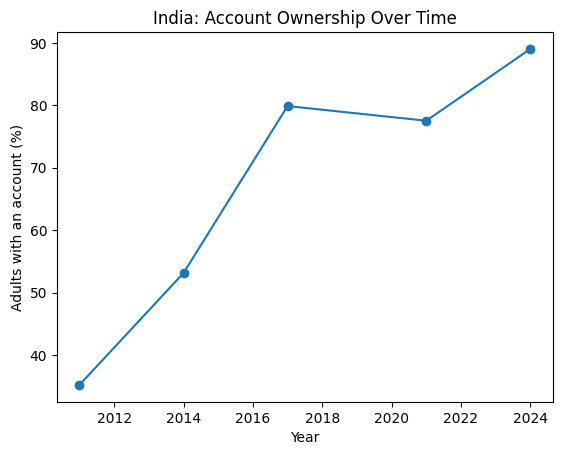

In [61]:
# PLOTTING ON GRAPH FOR CLEARER INFO

plt.plot(
    findex_all["year"],
    findex_all["account_t_d"] * 100,
    marker="o"
)

plt.xlabel("Year")
plt.ylabel("Adults with an account (%)")
plt.title("India: Account Ownership Over Time")

plt.show()

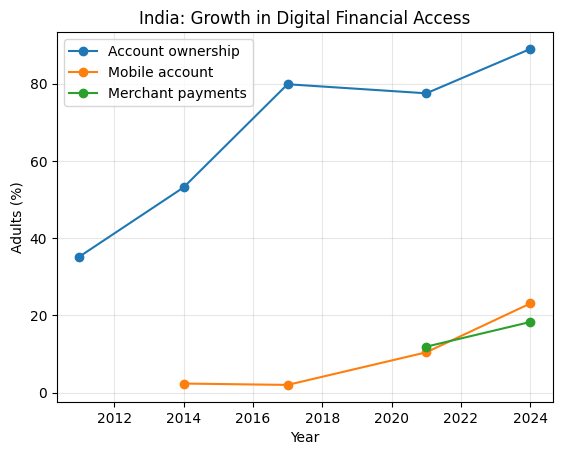

In [62]:
# ============================================
# FINDEX — DIGITAL FINANCIAL ACCESS
# ============================================

plt.plot(
    findex_all["year"],
    findex_all["account_t_d"] * 100,
    marker="o",
    label="Account ownership"
)

plt.plot(
    findex_all["year"],
    findex_all["mobileaccount_t_d"] * 100,
    marker="o",
    label="Mobile account"
)

plt.plot(
    findex_all["year"],
    findex_all["merchant_pay"] * 100,
    marker="o",
    label="Merchant payments"
)

plt.xlabel("Year")
plt.ylabel("Adults (%)")
plt.title("India: Growth in Digital Financial Access")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

In [63]:
# ============================================
# FINDEX: SAVING AND BORROWING OVER TIME
# ============================================

findex_trend = india_findex[
    (india_findex["group"] == "all") &
    (india_findex["group2"] == "all")
].copy()

# Keep the main indicators we need
findex_trend = findex_trend[
    ["year", "account_t_d", "save_any_t_d", "borrow_any_t_d"]
].sort_values("year")

print("India Findex: Saving and Borrowing Over Time")
print(findex_trend.to_string(index=False))

India Findex: Saving and Borrowing Over Time
 year  account_t_d  save_any_t_d  borrow_any_t_d
 2011     0.352318           NaN             NaN
 2014     0.531416      0.382760        0.477884
 2017     0.798753      0.335567        0.423910
 2021     0.775291      0.235477        0.447941
 2024     0.890248      0.386468        0.633357


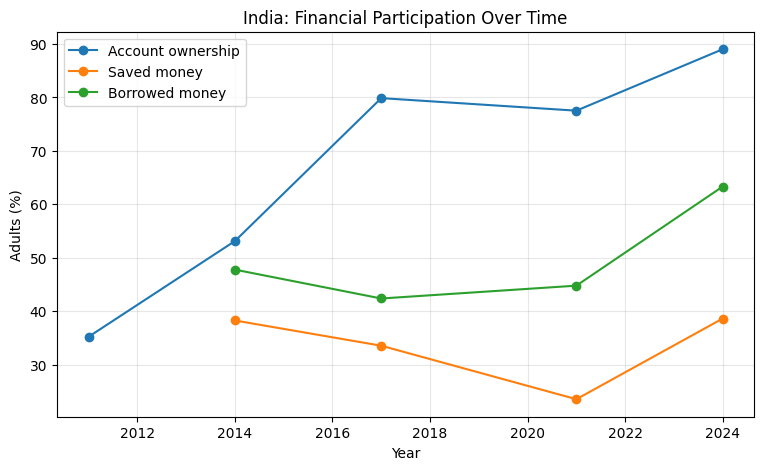

In [64]:
plt.figure(figsize=(9, 5))

plt.plot(
    findex_trend["year"],
    findex_trend["account_t_d"] * 100,
    marker="o",
    label="Account ownership"
)

plt.plot(
    findex_trend["year"],
    findex_trend["save_any_t_d"] * 100,
    marker="o",
    label="Saved money"
)

plt.plot(
    findex_trend["year"],
    findex_trend["borrow_any_t_d"] * 100,
    marker="o",
    label="Borrowed money"
)

plt.xlabel("Year")
plt.ylabel("Adults (%)")
plt.title("India: Financial Participation Over Time")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

In [65]:
# PLFS EDA NOW


In [66]:
# ============================================
# PLFS: INITIAL INSPECTION
# ============================================

print("PLFS shape:", plfs.shape)

print("\nColumns:")
print(plfs.columns.tolist())

print("\nFirst 5 rows:")
display(plfs.head())

PLFS shape: (401928, 39)

Columns:
['file_id', 'sch', 'qtr', 'month', 'visit', 'sec', 'st', 'dc', 'nss_reg', 'bstrm', 'strm', 'grp', 'sstrm', 'sro', 'mfsu', 'sss', 'ssu', 'smonth', 'resp_code', 'svc', 'rea_sub', 'hh_size', 'hhtype', 'relg', 'sg', 'hce_tot', 'lposs', 'llease', 'inc_tot', 'inf_srl', 'sur_date', 'sur_time', 'nsc', 'mult', 'totalsd', 'zst', 'caph', 'smallh', 'panel']

First 5 rows:


,file_id,sch,qtr,month,visit,sec,st,dc,nss_reg,bstrm,...,inf_srl,sur_date,sur_time,nsc,mult,totalsd,zst,caph,smallh,panel
0,QH1,104,Q2,4,V4,1,28,1,281,D001,...,2,16042025,25,6,817538,1,1161,169,4,5
1,QH1,104,Q2,4,V4,1,28,1,281,D001,...,2,17042025,25,6,193500,1,1161,60,6,5
2,QH1,104,Q2,4,V4,1,28,1,281,D001,...,2,17042025,22,6,1025550,1,1161,106,2,5
3,QH1,104,Q2,4,V4,1,28,1,281,D001,...,2,16042025,18,6,1025550,1,1161,106,2,5
4,QH1,104,Q2,4,V4,1,28,1,281,D001,...,2,16042025,26,6,817538,1,1161,169,4,5


In [67]:
# ============================================
# PLFS: VARIABLE QUALITY CHECK
# ============================================

print("Missing values:")
print(
    plfs.isnull()
    .sum()
    .sort_values(ascending=False)
)

print("\n" + "="*60)
print("DATA TYPES")
print("="*60)

print(plfs.dtypes)

Missing values:
rea_sub      395386
sch               0
file_id           0
month             0
visit             0
sec               0
qtr               0
st                0
dc                0
bstrm             0
nss_reg           0
grp               0
sstrm             0
sro               0
strm              0
mfsu              0
sss               0
smonth            0
ssu               0
resp_code         0
svc               0
hh_size           0
hhtype            0
relg              0
sg                0
hce_tot           0
lposs             0
llease            0
inc_tot           0
inf_srl           0
sur_date          0
sur_time          0
nsc               0
mult              0
totalsd           0
zst               0
caph              0
smallh            0
panel             0
dtype: int64

DATA TYPES
file_id       object
sch            int64
qtr           object
month          int64
visit         object
sec            int64
st             int64
dc             int64
nss_reg    

In [68]:
# ============================================
# PLFS: BASIC STATISTICS
# ============================================

print(plfs.describe(include="all").T)

              count unique   top    freq             mean             std  \
file_id      401928      1   QH1  401928              NaN             NaN   
sch        401928.0    NaN   NaN     NaN            104.0             0.0   
qtr          401928      3    Q2  134128              NaN             NaN   
month      401928.0    NaN   NaN     NaN         8.000353        2.582426   
visit        401928      4    V2  134002              NaN             NaN   
sec        401928.0    NaN   NaN     NaN         1.448889        0.497381   
st         401928.0    NaN   NaN     NaN        18.358694        9.659174   
dc         401928.0    NaN   NaN     NaN        18.071212       14.606363   
nss_reg    401928.0    NaN   NaN     NaN       185.973846       96.680674   
bstrm        401928    145  D007   17859              NaN             NaN   
strm       401928.0    NaN   NaN     NaN       119.186404       245.16285   
grp        401928.0    NaN   NaN     NaN         5.104954        3.520243   

In [69]:
# ============================================
# PLFS: SELECT RELEVANT VARIABLES
# ============================================

plfs_clean = plfs[
    [
        "st",
        "sec",
        "month",
        "hh_size",
        "hhtype",
        "relg",
        "sg",
        "hce_tot",
        "inc_tot"
    ]
].copy()

print("PLFS clean shape:", plfs_clean.shape)
print("\nColumns:")
print(plfs_clean.columns.tolist())

display(plfs_clean.head())

PLFS clean shape: (401928, 9)

Columns:
['st', 'sec', 'month', 'hh_size', 'hhtype', 'relg', 'sg', 'hce_tot', 'inc_tot']


,st,sec,month,hh_size,hhtype,relg,sg,hce_tot,inc_tot
0,28,1,4,3,1,1,9,14517,150
1,28,1,4,4,1,1,3,14575,110
2,28,1,4,3,5,1,2,11067,4100
3,28,1,4,2,9,1,9,8350,8250
4,28,1,4,4,1,1,2,14442,100


In [70]:
# ============================================
# PLFS: ECONOMIC VARIABLE DISTRIBUTIONS
# ============================================

print("INCOME (inc_tot)")
print(plfs_clean["inc_tot"].describe())

print("\n" + "="*50)

print("HOUSEHOLD CONSUMPTION EXPENDITURE (hce_tot)")
print(plfs_clean["hce_tot"].describe())

INCOME (inc_tot)
count    401928.000000
mean       4770.240526
std       10722.580389
min           0.000000
25%         125.000000
50%        1231.000000
75%        3650.000000
max      705000.000000
Name: inc_tot, dtype: float64

HOUSEHOLD CONSUMPTION EXPENDITURE (hce_tot)
count    401928.000000
mean      14352.900679
std        9122.432122
min         400.000000
25%        8667.000000
50%       12283.000000
75%       17633.000000
max      332333.000000
Name: hce_tot, dtype: float64


In [71]:
# ============================================
# PLFS: CLEAN DATABASE
# ============================================

plfs_clean = plfs[
    ['st', 'sec', 'month', 'hh_size', 'hhtype',
     'relg', 'sg', 'hce_tot', 'inc_tot']
].copy()

# Variables where 9/99 represent special/missing categories
# Convert obvious special codes to NaN
plfs_clean['hhtype'] = plfs_clean['hhtype'].replace(9, np.nan)
plfs_clean['relg'] = plfs_clean['relg'].replace(9, np.nan)
plfs_clean['sg'] = plfs_clean['sg'].replace(9, np.nan)

# Land possession: not using it yet, so ignore for now

# Income / expenditure must be non-negative
plfs_clean.loc[plfs_clean['inc_tot'] < 0, 'inc_tot'] = np.nan
plfs_clean.loc[plfs_clean['hce_tot'] < 0, 'hce_tot'] = np.nan

print("Clean PLFS shape:", plfs_clean.shape)

print("\nMissing values:")
print(plfs_clean.isna().sum())

print("\nIncome:")
print(plfs_clean['inc_tot'].describe())

print("\nConsumption:")
print(plfs_clean['hce_tot'].describe())

Clean PLFS shape: (401928, 9)

Missing values:
st              0
sec             0
month           0
hh_size         0
hhtype      33722
relg         1407
sg         107017
hce_tot         0
inc_tot         0
dtype: int64

Income:
count    401928.000000
mean       4770.240526
std       10722.580389
min           0.000000
25%         125.000000
50%        1231.000000
75%        3650.000000
max      705000.000000
Name: inc_tot, dtype: float64

Consumption:
count    401928.000000
mean      14352.900679
std        9122.432122
min         400.000000
25%        8667.000000
50%       12283.000000
75%       17633.000000
max      332333.000000
Name: hce_tot, dtype: float64


In [72]:
# ============================================
# PLFS → STATE-LEVEL SOCIOECONOMIC INDICATORS
# ============================================

plfs_state = (
    plfs_clean
    .groupby('st')
    .agg(
        plfs_median_income=('inc_tot', 'median'),
        plfs_mean_income=('inc_tot', 'mean'),
        plfs_median_consumption=('hce_tot', 'median'),
        plfs_mean_consumption=('hce_tot', 'mean'),
        plfs_median_hh_size=('hh_size', 'median')
    )
    .reset_index()
)

# Income relative to consumption
plfs_state['plfs_income_consumption_ratio'] = (
    plfs_state['plfs_median_income'] /
    plfs_state['plfs_median_consumption']
)

print("PLFS state-level shape:", plfs_state.shape)
display(plfs_state)

PLFS state-level shape: (36, 7)


,st,plfs_median_income,plfs_mean_income,plfs_median_consumption,plfs_mean_consumption,plfs_median_hh_size,plfs_income_consumption_ratio
0,1,800.0,7006.087544,15517.0,17401.025334,4.0,0.051556
1,2,2220.0,11063.513454,11817.0,14165.285933,3.0,0.187865
2,3,1000.0,6861.757376,16750.0,18772.186606,4.0,0.059701
3,4,770.0,12334.413712,20518.0,25349.762411,4.0,0.037528
4,5,1500.0,6516.234565,12958.0,14493.792977,4.0,0.115759
5,6,2210.0,6647.761996,14583.0,16981.840408,4.0,0.151546
6,7,450.0,7041.845749,17000.0,18710.795242,4.0,0.026471
7,8,1150.0,5172.840522,13583.0,15254.052705,4.0,0.084665
8,9,215.0,3711.077003,9900.0,11469.344168,5.0,0.021717
9,10,500.0,4102.740629,10200.0,11205.302326,5.0,0.049020


In [73]:
print("PLFS state codes:")
print(sorted(plfs_state['st'].unique()))

print("\nGiving dataset State values:")
print(sorted(X['State'].dropna().unique()))

PLFS state codes:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(31), np.int64(32), np.int64(33), np.int64(34), np.int64(35), np.int64(36), np.int64(37)]

Giving dataset State values:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(7), np.int64(8), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(22), np.int64(23), np.int64(24), np.int64(25)]


In [74]:
# ============================================
# MERGE PLFS STATE-LEVEL FEATURES
# ============================================

X_plfs = X.copy()

X_plfs = X_plfs.merge(
    plfs_state,
    left_on='State',
    right_on='st',
    how='left'
)

# We don't need the duplicate PLFS state column
X_plfs.drop(columns=['st'], inplace=True)

print("Original X shape:", X.shape)
print("After PLFS merge:", X_plfs.shape)

print("\nNew PLFS features:")
print([
    col for col in X_plfs.columns
    if col.startswith('plfs_')
])

print("\nMissing PLFS values:")
print(X_plfs.filter(like='plfs_').isna().sum())

Original X shape: (7225, 48)
After PLFS merge: (7225, 54)

New PLFS features:
['plfs_median_income', 'plfs_mean_income', 'plfs_median_consumption', 'plfs_mean_consumption', 'plfs_median_hh_size', 'plfs_income_consumption_ratio']

Missing PLFS values:
plfs_median_income               0
plfs_mean_income                 0
plfs_median_consumption          0
plfs_mean_consumption            0
plfs_median_hh_size              0
plfs_income_consumption_ratio    0
dtype: int64


In [75]:
# ============================================================
# FINAL CLEAN PLFS MERGE
# Target = overall_cash_giving
# ============================================================

# Start from X
X_plfs = X.copy()

# Variables that describe giving behavior / outcomes
# These should NOT be predictors of cash giving.
giving_leakage = [
    'cash_none',
    'cash_refused',
    'cash_in-kind_giving',

    'in-kind_family_friends',
    'in-kind_beggars',
    'in-kind_religious_orgs',
    'in-kind_non-religious_orgs',
    'overall_in-kind_giving',
    'in-kind_none',
    'in-kind_refused',

    'volunteer_religious',
    'volunteer_non-religious',
    'overall_volunteer',
    'volunteer_none',
    'volunteer_refused',

    'Recipient_religious',
    'Recipient_non.religious',
    'Recipient_beggars',
    'Recipient_family_friends'
]

# Remove only columns that actually exist
X_plfs = X_plfs.drop(
    columns=[c for c in giving_leakage if c in X_plfs.columns],
    errors='ignore'
)

# Merge PLFS state-level data
X_plfs = X_plfs.merge(
    plfs_state,
    left_on='State',
    right_on='st',
    how='left'
)

# Remove duplicate PLFS state-code column
if 'st' in X_plfs.columns:
    X_plfs = X_plfs.drop(columns=['st'])

print("Final X_plfs shape:", X_plfs.shape)

print("\nPLFS features added:")
print([
    'plfs_median_income',
    'plfs_mean_income',
    'plfs_median_consumption',
    'plfs_mean_consumption',
    'plfs_median_hh_size',
    'plfs_income_consumption_ratio'
])

print("\nRemaining giving-related columns:")
print([
    c for c in giving_leakage
    if c in X_plfs.columns
])

Final X_plfs shape: (7225, 35)

PLFS features added:
['plfs_median_income', 'plfs_mean_income', 'plfs_median_consumption', 'plfs_mean_consumption', 'plfs_median_hh_size', 'plfs_income_consumption_ratio']

Remaining giving-related columns:
[]


In [76]:
print(X_plfs.shape)
print(X_plfs.columns.tolist())

(7225, 35)
['State', 'learning_channel', 'learning_channel_combinedSM', 'television', 'electric_fan', 'air_conditioner', 'bicycle', 'two_wheeler', 'washing_machine', 'computer', 'car_or_heavy_vehicle', 'HH_position', 'gender', 'age', 'state', 'residence_type', 'district', 'religion', 'social_category', 'highest_education', 'combined_ages', 'region', 'assetclass', 'overall_giving', 'cons', 'consumption category', 'Edu category', 'Archetype', 'avg_HH_Size_FDQ_lvl3', 'plfs_median_income', 'plfs_mean_income', 'plfs_median_consumption', 'plfs_mean_consumption', 'plfs_median_hh_size', 'plfs_income_consumption_ratio']


In [77]:
# Remove overall giving
X_plfs = X_plfs.drop(
    columns=['overall_giving'],
    errors='ignore'
)

print("Final X_plfs shape:", X_plfs.shape)
print("Overall giving present:", 'overall_giving' in X_plfs.columns)

print("\nFinal features:")
print(X_plfs.columns.tolist())

Final X_plfs shape: (7225, 34)
Overall giving present: False

Final features:
['State', 'learning_channel', 'learning_channel_combinedSM', 'television', 'electric_fan', 'air_conditioner', 'bicycle', 'two_wheeler', 'washing_machine', 'computer', 'car_or_heavy_vehicle', 'HH_position', 'gender', 'age', 'state', 'residence_type', 'district', 'religion', 'social_category', 'highest_education', 'combined_ages', 'region', 'assetclass', 'cons', 'consumption category', 'Edu category', 'Archetype', 'avg_HH_Size_FDQ_lvl3', 'plfs_median_income', 'plfs_mean_income', 'plfs_median_consumption', 'plfs_mean_consumption', 'plfs_median_hh_size', 'plfs_income_consumption_ratio']


In [78]:
# TRAINING DATA

In [79]:
import matplotlib.pyplot as plt

# ============================================
# TRAINING — CLEAN BASELINE
# ============================================

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# --------------------------------------------
# X and TARGET
# --------------------------------------------

X = X_plfs.copy()
y = y.copy() # Changed TARGET.copy() to y.copy()

print("X shape:", X.shape)
print("Target shape:", y.shape)

# --------------------------------------------
# TRAIN / TEST SPLIT
# --------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining:", X_train.shape)
print("Testing :", X_test.shape)

# --------------------------------------------
# IDENTIFY COLUMN TYPES
# --------------------------------------------

categorical_cols = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_cols = X_train.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns.tolist()

print("\nNumerical columns:", len(numerical_cols))
print("Categorical columns:", len(categorical_cols))

# --------------------------------------------
# PREPROCESSING
# --------------------------------------------

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

# --------------------------------------------
# LOGISTIC REGRESSION
# --------------------------------------------

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

# --------------------------------------------
# TRAIN
# --------------------------------------------

logistic_model.fit(X_train, y_train)

# --------------------------------------------
# PREDICTIONS
# --------------------------------------------

y_pred = logistic_model.predict(X_test)
y_prob = logistic_model.predict_proba(X_test)[:, 1]

# --------------------------------------------
# RESULTS
# --------------------------------------------

print("\n=== LOGISTIC REGRESSION — CLEAN MODEL ===")

print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred):.4f}")
print(f"F1 Score : {f1_score(y_test, y_pred):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_prob):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

X shape: (7225, 34)
Target shape: (7225,)

Training: (5780, 34)
Testing : (1445, 34)

Numerical columns: 28
Categorical columns: 6

=== LOGISTIC REGRESSION — CLEAN MODEL ===
Accuracy : 0.6436
Precision: 0.5898
Recall   : 0.6780
F1 Score : 0.6308
ROC-AUC  : 0.6983

Confusion Matrix:
[[490 306]
 [209 440]]

Classification Report:
              precision    recall  f1-score   support

           0       0.70      0.62      0.66       796
           1       0.59      0.68      0.63       649

    accuracy                           0.64      1445
   macro avg       0.65      0.65      0.64      1445
weighted avg       0.65      0.64      0.64      1445



In [80]:
import matplotlib.pyplot as plt

# ============================================
# RANDOM FOREST + PLFS
# ============================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# --------------------------------------------
# DATA
# --------------------------------------------

X = X_plfs.copy()
y = y.copy()

# SAME SPLIT AS BEFORE
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# --------------------------------------------
# COLUMN TYPES
# --------------------------------------------

categorical_cols = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_cols = X_train.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns.tolist()

print("Numerical:", len(numerical_cols))
print("Categorical:", len(categorical_cols))

# --------------------------------------------
# PREPROCESSING
# --------------------------------------------

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

# --------------------------------------------
# RANDOM FOREST
# --------------------------------------------

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=500,
        max_depth=None,
        min_samples_split=5,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# --------------------------------------------
# TRAIN
# --------------------------------------------

rf_model.fit(X_train, y_train)

# --------------------------------------------
# PREDICTIONS
# --------------------------------------------

y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

# --------------------------------------------
# RESULTS
# --------------------------------------------

print("\n=== RANDOM FOREST + PLFS ===")

print(f"Accuracy : {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_rf):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred_rf):.4f}")
print(f"F1 Score : {f1_score(y_test, y_pred_rf):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_prob_rf):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Numerical: 28
Categorical: 6

=== RANDOM FOREST + PLFS ===
Accuracy : 0.6519
Precision: 0.6070
Recall   : 0.6379
F1 Score : 0.6221
ROC-AUC  : 0.7054

Confusion Matrix:
[[528 268]
 [235 414]]

Classification Report:
              precision    recall  f1-score   support

           0       0.69      0.66      0.68       796
           1       0.61      0.64      0.62       649

    accuracy                           0.65      1445
   macro avg       0.65      0.65      0.65      1445
weighted avg       0.65      0.65      0.65      1445



In [81]:
#RANDOM FOREST + PLFS IS BETTER. USING THAT FOR PREDICTIVE MODEL

In [82]:
import joblib

joblib.dump(rf_model, "cash_giving_random_forest.pkl")
joblib.dump(preprocessor, "cash_giving_preprocessor.pkl")

print("Model and preprocessor saved!")

Model and preprocessor saved!


In [83]:
def predict_cash_giving(input_data):
    input_df = pd.DataFrame([input_data])

    X_processed = preprocessor.transform(input_df)

    prediction = rf_model.predict(X_processed)[0]
    probability = rf_model.predict_proba(X_processed)[0][1]

    return {
        "prediction": int(prediction),
        "probability": float(probability)
    }

In [84]:
# SAVED PREDICTION DATASET, MODEL IN JOBLIB AND FUNCTION TO CALL. BUILD UI NEXT STEP.

In [95]:
# UI

import ipywidgets as w
from IPython.display import display, clear_output
import pandas as pd

features = preprocessor.feature_names_in_.tolist()

states = sorted(X_plfs["state"].dropna().unique())

age = w.IntText(value=36, description="Age")
state = w.Dropdown(options=states, description="State")
district = w.Dropdown(description="District")
gender = w.Dropdown(options=["Male","Female"], description="Gender")
hh = w.IntText(value=4, description="Household Size")
cons = w.FloatText(value=5846, description="Consumption")

button = w.Button(description="Predict Donation", button_style="primary")
out = w.Output()

def update_district(change=None):
    s = state.value
    district.options = sorted(
        X_plfs.loc[X_plfs["state"] == s, "district"]
        .dropna().unique()
    )

state.observe(update_district, names="value")
update_district()

display(
    w.VBox([
        w.HTML("<h3>Donor Prediction</h3>"),
        age, gender, state, district, hh, cons,
        button, out
    ])
)

def predict(_):
    with out:
        clear_output()

        s = state.value
        d = district.value
        subset = X_plfs[X_plfs["state"] == s]

        row = {}

        for col in features:
            if pd.api.types.is_numeric_dtype(subset[col]):
                row[col] = subset[col].median()
            else:
                row[col] = subset[col].mode()[0]

        row["state"] = s
        row["district"] = d
        row["age"] = age.value
        row["gender"] = 1 if gender.value == "Male" else 2
        row["avg_HH_Size_FDQ_lvl3"] = hh.value
        row["cons"] = cons.value

        info = X_plfs[X_plfs["state"] == s].iloc[0]
        row["State"] = info["State"]
        row["region"] = info["region"]

        row = pd.DataFrame([row])[features]

        p = rf_model.predict_proba(row)[0, 1]
        print(f"Donation probability: {p:.1%}")
        print("Likely to donate" if p >= 0.5 else "Less likely to donate")

button.on_click(predict)